In [3]:
import gc
import hashlib
import os
import pickle
import sys
from pathlib import Path
from typing import Any

import joblib
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.metrics import (
    make_scorer,
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
import yaml
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

sys.path.insert(0, str(Path.cwd().parent))

from utils.geo import (
    LOCALITY_ALIASES,
    classify_city,
    fill_locality,
    inside_bbox_mask,
    locality_price_outliers,
    snap_locality,
    add_landmark_distances,
)
from utils.preprocessing import (
    FrequencyEncoder,
    NearestNeighborImputer,
    OutlierFilterRegressor,
    amenity_feature_names,
    amenity_features,
    clip_round,
    grouped_feature_name,
    impute_bimodal,
    log_feature_names,
    months_listed,
    months_listed_names,
)
from utils.map_graph import create_map, show_map
from utils.triple_plot import normality_report
# Every step returns a DataFrame, so later steps can pick columns by name.
set_config(transform_output="pandas")

ROOT_DIR = Path.cwd().parent

DATA_DIR = ROOT_DIR / "data"

GEO_DIR = ROOT_DIR / "geodata"

In [4]:
def acc_within_10(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Proporción de inmuebles estimados dentro del ±10% del valor real.

    Evalúa la precisión dentro del rango óptimo de negociación comercial.
    Un porcentaje mayor indica una alta densidad de estimaciones listas
    para cierre de negocio sin fricción de precio.
    """
    errores_pct = np.abs((y_pred - y_true) / y_true)
    return float(np.mean(errores_pct <= 0.10) * 100)


def acc_within_20(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Proporción de inmuebles estimados dentro del ±20% del valor real.

    Mide el cumplimiento de la banda máxima de tolerancia aceptable en AVM.
    Permite identificar qué porcentaje del portafolio se mantiene en un rango
    operativamente defendible antes de considerar la estimación como errónea.
    """
    errores_pct = np.abs((y_pred - y_true) / y_true)
    return float(np.mean(errores_pct <= 0.20) * 100)


def sobreprediccion_rate(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Porcentaje de inmuebles donde la predicción supera el valor real (y_pred > y_true).

    Cuantifica el riesgo de sobreprecio en el mercado. Un porcentaje elevado
    (>50%) indica sesgo positivo, lo que incrementa el riesgo de estancar los
    inmuebles en portales inmobiliarios al superar la disposición a pagar.
    """
    return float(np.mean(y_pred > y_true) * 100)


# --- Diccionario de Scorers Completo para CV ---
METRICAS_CV = {
    # Métricas estándar de sklearn (se minimizan, requieren neg_)
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "MAPE": "neg_mean_absolute_percentage_error",
    "R2": "r2",
    # Métricas comerciales (se maximizan / monitorean directamente)
    "Acc_10": make_scorer(acc_within_10, greater_is_better=True),
    "Acc_20": make_scorer(acc_within_20, greater_is_better=True),
    "Sobreprediccion": make_scorer(
        sobreprediccion_rate, greater_is_better=False
    ),
}

In [5]:
## load yamls
bogota_marks_yaml_path = GEO_DIR / "bogota_landmarks.yaml"
with open(bogota_marks_yaml_path, "r", encoding="utf-8") as file:
    geo_data = yaml.safe_load(file)

In [6]:
positive_landmarks = geo_data.get("positive_landmarks", {})
negative_landmarks = geo_data.get("negative_landmarks", {})


# Implementación de BART basado en Cao et al. (2024)

En este cuaderno se adapta la metodología de recortes adaptativos (*adaptive trimming*) desarrollada por **Cao et al. (2024)** para modelos BART (*Bayesian Additive Regression Trees*), la cual permite identificar y filtrar iterativamente las observaciones anómalas o atípicas (*outliers*) de la muestra sin perder rigurosidad en la estimación. Adicionalmente, se compara el desempeño predictivo de esta propuesta frente a las metodologías econométricas y de aprendizaje automático consolidadas en la literatura de avalúos masivos.

El cuaderno recupera las fases de limpieza y depuración previas y las integra dentro de una *pipeline* de *Machine Learning* que implementa la partición estándar y la validación cruzada (*Cross-Validation*), siguiendo el esquema de evaluación fuera de muestra (*out-of-sample*) planteado por **Lozano-Gracia y Anselin (2012)**. De acuerdo con los hallazgos de estos mismos autores para Bogotá, se sustituye la recolección presencial y costosa de zonas homogéneas por la extracción automatizada de variables geodésicas calculadas mediante Sistemas de Información Geográfica (SIG), estructurando tres nuevas columnas de distancia espacial:

1. **Distancia a la estación de TransMilenio más cercana**: Variable que mide la accesibilidad al sistema de transporte masivo, un atributo clave que condiciona la disposición a pagar de los hogares y la estructuración del valor del suelo según la revisión teórica realizada por **Chang (2006)**.
2. **Distancia al** **landmark** **'positivo' más cercano**: Atributo que capta la revalorizacion generada por amenidades urbanas y espacios públicos. Al respecto, **Villada-Medina et al. (2023)** demuestran empíricamente en el contexto colombiano la valorización directa que ejercen los centros comerciales en el precio de la vivienda (con incrementos de entre 3.59% y 7.39% en radios de influencia de 0.5 km), mientras que **Loret de Mola et al. (2017)** resaltan la alta prioridad económica que los compradores de megaciudades latinoamericanas otorgan a la presencia de parques y áreas verdes metropolitanas.
3. **Distancia al** **landmark** **'negativo' más cercano**: Variable diseñada para registrar la penalización sobre el precio por metro cuadrado ocasionada por la proximidad a desamenidades o sectores de deterioro urbano (tales como la Cárcel La Modelo, El Bronx o San Bernardo). Esta aproximación se ampara en los desarrollos de **Tapia et al. (2025)** e **Iban (2022)**, quienes integran explícitamente en sus modelos de valuación masiva las distancias a penitenciarías, zonas industriales y depósitos de desechos para capturar el descuento comercial asociado a estas externalidades negativas.

# Recuperar el df original.

En esta seccion  se retoma el mismo df que se tuvo inicialmente, se recuperan las elimiaciones de atipicos y de calidad general realizados en `notebooks/data_cleaning.ipynb` y dentro de un pipeline basado en `notenooks/data_preparation.ipynb` se agregan las nuevas distancias a landmarks planteadas, adicionalmente de esta seccion se espera como resultado 2 df, uno con varias variables transformadas en log para el usar modelos como OLS y otro sin las varaibles escaladas o trasnformadas mas alla de una pipeline de inputacion y codificacion para los modelos de arbol como XGBoost o BART.

Se plantea usar como variable objetivo el precio del inmueble, para los modelos OLS tanto en arboles se utiliza el precio en log, y usando el objeto `TransformedTargetRegressor` para regresar a la unidad interpretable.

In [7]:
df = pd.read_csv(DATA_DIR / "fincaraiz_venta_bogota_20260803.csv")

In [8]:
sizes = {"Inicial": len(df)}

## Limpieza previa al pipeline

Antes del pipeline solo se hace lo que no aprende nada de los datos: quitar
columnas sin uso, restringir la base a la población de estudio y corregir los
registros inconsistentes de `notebooks/data_cleaning.ipynb`. Como ninguno de
estos pasos estima un parámetro, aplicarlos a toda la base antes de la partición
no filtra información del conjunto de prueba. Además, varios eliminan filas, y
un paso de sklearn no puede hacerlo.

Lo que sí se estima con los datos (imputación, umbrales IQR, codificación) queda
dentro del pipeline, para que se reaprenda en cada *fold* de la validación
cruzada.

### Columnas sin uso y moneda

Se eliminan los identificadores, la URL, la dirección y `total_monthly_cost`.
Un único inmueble está cotizado en `U$S` y casi vacío; al quitarlo,
`price_currency` queda constante y también se elimina.

In [9]:
df = df.drop(
    columns=[
        "listing_id",
        "operation",
        "source_url",
        "total_monthly_cost",
        "address_text",
    ]
)
df = df[df["price_currency"] != "U$S"].drop(columns="price_currency")
sizes["Moneda COP"] = len(df)

### Solo vivienda

El análisis se limita a uso residencial, así que se descartan los inmuebles
comerciales. `cabana` también sale: tiene un solo registro.

In [10]:
residential = [
    "casa",
    "apartamento",
    "apartaestudio",
    "casa_campestre",
    "habitacion",
    "finca",
]
df = df[df["property_type"].isin(residential)]
sizes["Vivienda"] = len(df)

### Variables discretas inconsistentes

- `bedrooms`: −1 y 0 no son cantidades válidas, se vuelven `NaN`.
- `bathrooms`: 0 se vuelve `NaN`.
- `parking_spaces`: −1 y −2 se corrigen a 1 y 2.
- `floor`: valores como 101, 301 o 502 se dividen entre 100 y se redondean.
- `stratum`: debe estar entre 1 y 6; valores como 110 no permiten saber el
  estrato real, así que esas filas se eliminan.

In [11]:
df["bedrooms"] = df["bedrooms"].replace([-1, 0], np.nan)
df["bathrooms"] = df["bathrooms"].replace(0, np.nan)
df["parking_spaces"] = df["parking_spaces"].replace({-1: 1, -2: 2})
df["floor"] = df["floor"].where(
    df["floor"] <= 100, (df["floor"] / 100).round()
)
df = df[~(df["stratum"] > 6)]  # NaN strata are kept for imputation
sizes["Estrato válido"] = len(df)

### Rango de precios del estudio

Se conservan los precios entre \$30 millones y \$1 billón. Por debajo hay
precios de 0 o 1 peso y cifras que parecen arriendos; por encima hay un error
de digitación. No son precios de venta reales, así que este rango define la
población y se aplica antes de la partición.

Si quedara dentro del pipeline, el filtro de atípicos los sacaría del
entrenamiento pero seguirían en los *folds* de prueba: un inmueble de 1 peso
basta para que el MAPE de un *fold* llegue a 200.000.

In [12]:
df = df[df["price_amount"].between(30_000_000, 1_000_000_000_000)]
sizes["Rango de precio"] = len(df)

### Atípicos de precio por localidad

Se eliminan los precios por fuera de 2.5 × IQR de su propia localidad, como en la
sección *Check coordinates quality* de `data_cleaning.ipynb`, con dos
correcciones:

1. **Nombres.** El sitio escribe "Usaquen", "Santafe", "Ciudad Bolivar" y los
   recuadros usan "Usaquén", "Santa Fe", "Ciudad Bolívar". En el cuaderno
   original la mitad de las localidades no coincidía y nunca se revisaba, entre
   ellas Usaquén, el mercado más grande. Ahora se normalizan con
   `LOCALITY_ALIASES`.
2. **Solo la localidad propia.** Los recuadros se superponen. Con los nombres
   ya corregidos, revisar cada punto contra todos los recuadros en los que cae
   hacía que los umbrales de Engativá eliminaran 1.591 inmuebles de Suba y
   Barrios Unidos, ninguno de Engativá. Cada fila se compara solo con los
   umbrales de su localidad, y solo si sus coordenadas caen en ese recuadro.

In [13]:
df["locality"] = df["locality"].replace(LOCALITY_ALIASES)
locality_outliers = locality_price_outliers(df, multiplier=2.5)
print(
    f"locality price outliers: {locality_outliers.sum()} "
    f"({locality_outliers.mean():.2%})"
)
df = df[~locality_outliers]
sizes["Atípicos por localidad"] = len(df)

locality price outliers: 567 (2.49%)


### Ciudad y localidad desde las coordenadas

`city` se reescribe a partir de la latitud y la longitud; los inmuebles por
fuera de Cundinamarca se eliminan. Las pocas ciudades que no caen en ningún
municipio quedan en `NaN` y se imputan en el pipeline.

`locality` se completa con el recuadro más pequeño que contiene el punto y luego
con el borde más cercano a menos de 0.02°. Las filas que siguen sin localidad
tienen coordenadas que no corresponden a Bogotá y se eliminan.

In [14]:
df["city"] = classify_city(df["latitude"], df["longitude"])
df = df[inside_bbox_mask(df["latitude"], df["longitude"])]
sizes["Dentro de Cundinamarca"] = len(df)

df["locality"] = snap_locality(
    fill_locality(df["locality"], df["latitude"], df["longitude"]),
    df["latitude"],
    df["longitude"],
)
df = df[df["locality"].notna()]
sizes["Localidad ubicable"] = len(df)

### Columnas descartadas en los cuadernos previos

| Columna | Motivo |
|---|---|
| `floors_total` | 71 % de faltantes; `floor` da información similar |
| `age_bracket_label` | Equivale 1 a 1 a `age_bracket_code` |
| `agency_name` | Sesgaría el modelo hacia quién vende y no hacia el inmueble |
| `updated_at` | No se usa |
| `price_per_m2` | Se calcula con el precio: dejarla filtraría la variable objetivo |

`area_private_m2` se conserva hasta la codificación, porque la usan MICE y las
reglas de negocio, y allí se elimina por VIF. `published_at` se convierte en
`meses_ofertado` dentro del pipeline.

In [15]:
df = df.drop(
    columns=[
        "floors_total",
        "age_bracket_label",
        "agency_name",
        "updated_at",
        "price_per_m2",
    ]
).reset_index(drop=True)

steps = pd.Series(sizes, name="Filas").to_frame()
steps["% del inicial"] = (100 * steps["Filas"] / sizes["Inicial"]).round(2)
steps

,Filas,% del inicial
Inicial,31252,100.00
Moneda COP,31251,100.00
Vivienda,22853,73.12
Estrato válido,22754,72.81
Rango de precio,22729,72.73
Atípicos por localidad,22162,70.91
Dentro de Cundinamarca,22146,70.86
Localidad ubicable,22144,70.86


Faltantes que le quedan al pipeline:

In [16]:
(
    df.isna()
    .mean()
    .mul(100)
    .round(2)
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
    .rename("% faltante")
)

floor                 44.16
admin_fee             34.51
parking_spaces        25.61
area_private_m2       21.60
area_built_m2         15.59
amenities              7.86
construction_state     4.47
publisher_type         4.38
age_bracket_code       2.48
stratum                2.19
bedrooms               0.69
bathrooms              0.53
neighborhood           0.03
Name: % faltante, dtype: float64

## Crear variables de distancia a landmarks

In [17]:
df_pos = pd.DataFrame.from_dict(
    positive_landmarks,
    orient="index").assign(label="positive")
df_neg = pd.DataFrame.from_dict(
    negative_landmarks,
    orient="index").assign(label="negative")
df_landmarks = pd.concat([df_pos, df_neg])
df_landmarks = df_landmarks.reset_index().rename(columns={"index": "landmark_name"})

In [18]:
show_map(
    create_map(
        df_landmarks,
        name_col="landmark_name",
        label_col="label",
        colors={"positive": "green", "negative": "red"},
        cluster=False,
    )
)

In [19]:
df = add_landmark_distances(df_houses=df, df_landmarks=df_landmarks)

In [20]:
df

,property_type,price_amount,admin_fee,area_built_m2,area_private_m2,bedrooms,bathrooms,parking_spaces,stratum,floor,...,city,locality,neighborhood,latitude,longitude,amenities,publisher_type,published_at,dist_nearest_positive_km,dist_nearest_negative_km
0,casa,8.800000e+08,736000.0,160.0,151.0,3.0,3.0,2.0,4.0,NaN,...,Bogotá,Suba,UB. Hacienda Cordoba Niza,4.711642,-74.062946,Alarma|Baño Auxiliar|Calentador|Canchas Deport...,NaN,2023-01-24,2.455983,3.573925
1,casa,6.500000e+08,NaN,153.4,153.4,4.0,2.0,1.0,3.0,NaN,...,Bogotá,Barrios Unidos,Benjamin Herrera,4.655459,-74.073723,Baño Auxiliar|Colegios / Universidades|Estudio...,NaN,2023-01-31,2.026489,0.860543
2,casa,6.250000e+08,643500.0,120.0,120.0,4.0,3.0,2.0,5.0,1.0,...,Bogotá,Usaquén,Lagos DE Torca,4.764007,-74.042742,Baño Auxiliar|Calentador|Cancha de Tennis|Canc...,NaN,2023-02-08,3.806538,1.061929
3,apartamento,4.700000e+08,560000.0,56.0,58.0,1.0,2.0,1.0,4.0,2.0,...,Bogotá,Usaquén,Cedritos,4.721554,-74.036146,Ascensor|Barra estilo americano|Baño Auxiliar|...,NaN,2023-03-01,0.873108,1.940358
4,casa,3.300000e+09,NaN,NaN,350.0,4.0,3.0,2.0,6.0,2.0,...,Bogotá,Suba,San Jose DE Bavaria,4.769128,-74.061616,Balcón|Barra estilo americano|Baño Auxiliar|Ch...,inmobiliaria,2023-03-22,3.869940,2.313233
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22139,casa,5.799000e+08,NaN,NaN,192.0,6.0,3.0,1.0,3.0,NaN,...,Bogotá,Fontibón,Centro Fontibon,4.676469,-74.136465,Alcantarillado|Baño Auxiliar|Cerca centro come...,inmobiliaria,2023-10-12,0.919885,0.240636
22140,casa,6.000000e+08,NaN,NaN,126.0,5.0,3.0,1.0,3.0,NaN,...,Bogotá,Engativá,Lujan,4.682503,-74.099924,Cerca a sector comercial|Cerca centro comercia...,inmobiliaria,2023-10-12,1.612638,2.898134
22141,apartamento,6.500000e+08,NaN,NaN,90.0,3.0,3.0,1.0,4.0,NaN,...,Bogotá,Teusaquillo,EL Recuerdo,4.628558,-74.083638,Ascensor|Baño Auxiliar|Calentador|Cerca a sect...,inmobiliaria,2023-11-02,1.202839,1.833696
22142,apartamento,1.870000e+08,NaN,NaN,41.0,2.0,1.0,NaN,2.0,NaN,...,Bogotá,Suba,Pinar DE Suba,4.755939,-74.078061,NaN,inmobiliaria,2023-11-03,1.611158,2.063461


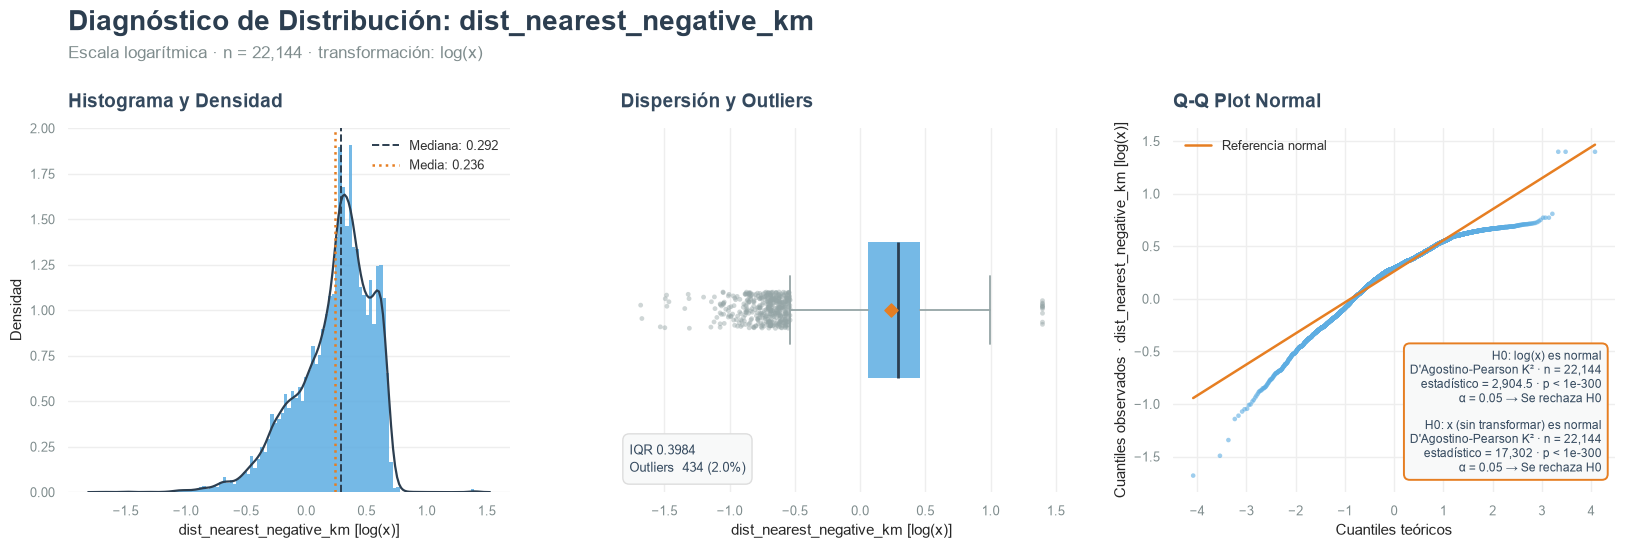

In [28]:
norm_pos = normality_report(df, 'dist_nearest_negative_km', log_transformation=True)

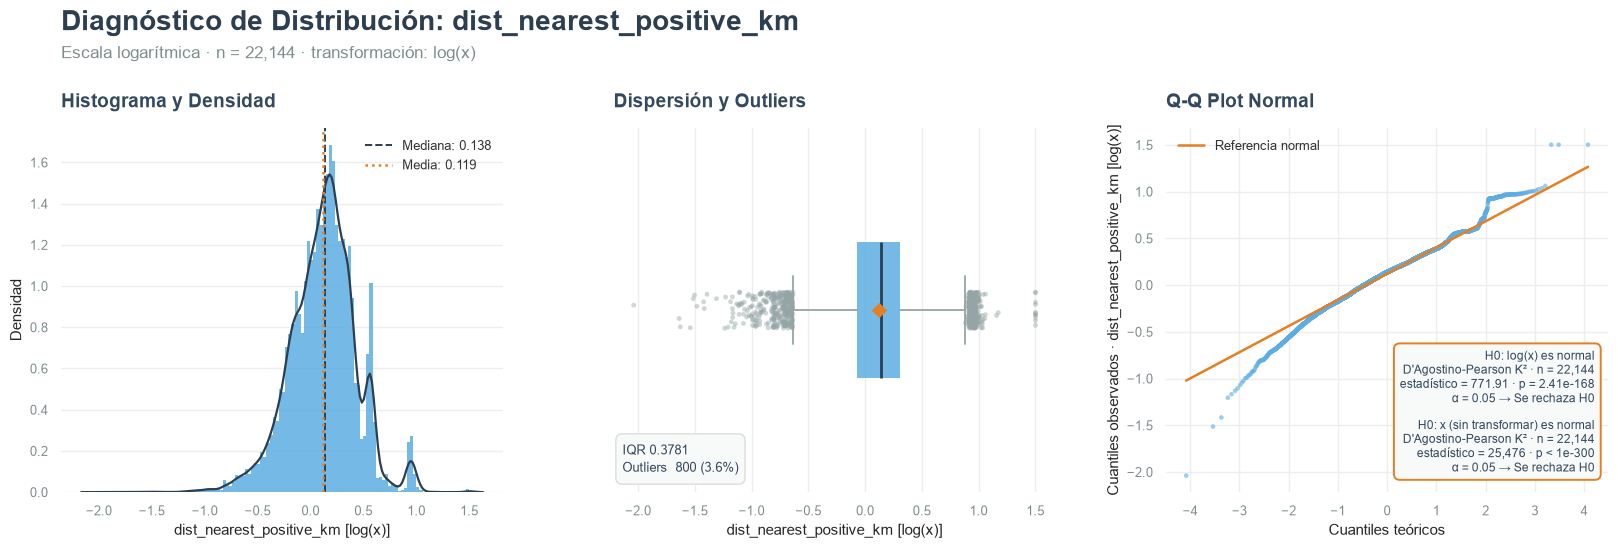

In [29]:
neg_pos = normality_report(df, 'dist_nearest_positive_km', log_transformation=True)

## Partición

La variable objetivo es `price_amount`, en pesos. El logaritmo se aplica dentro
del pipeline con `TransformedTargetRegressor`.


In [13]:
X = df.drop(columns="price_amount")
y = df["price_amount"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((17715, 19), (4429, 19))

In [14]:
X.head(3).T

,0,1,2
property_type,casa,casa,casa
admin_fee,736000.0,NaN,643500.0
area_built_m2,160.0,153.4,120.0
area_private_m2,151.0,153.4,120.0
bedrooms,3.0,4.0,4.0
bathrooms,3.0,2.0,3.0
parking_spaces,2.0,1.0,2.0
stratum,4.0,3.0,5.0
floor,NaN,NaN,1.0
age_bracket_code,4.0,5.0,4.0


## Pipeline

```
Pipeline
├── imputation                      (se ajusta con todas las filas de entrenamiento)
│   ├── simple    moda, bimodal, 1-NN, constantes
│   └── mice      IterativeImputer + ExtraTrees
└── outliers      OutlierFilterRegressor   ← elimina filas solo al ajustar
    └── TransformedTargetRegressor (log / exp)
        └── Pipeline
            ├── encoding    one-hot, frecuencia, meses_ofertado
            ├── amenities   banderas y conteo de amenidades
            └── model       DummyRegressor (provisional)
```

Un paso de sklearn debe devolver tantas filas como recibe, así que ningún
transformador puede eliminar atípicos. Por eso `OutlierFilterRegressor`
**envuelve** los pasos que vienen después de él. Al ajustar elimina las filas
atípicas de `X` y de `y` y entrena el resto solo con las filas que quedan. Al
predecir deja pasar todas las filas: un inmueble de prueba nunca se descarta,
simplemente el modelo no aprendió de los atípicos.

El `TransformedTargetRegressor` va dentro del filtro y no alrededor de él, para
que las reglas lean el precio en pesos, igual que en `data_cleaning.ipynb`.

### 1. Imputación

Se hace en dos etapas porque MICE, en `data_cleaning.ipynb`, se ajustó cuando
las imputaciones simples ya estaban hechas.

| Variable | Método | Origen |
|---|---|---|
| `city`, `construction_state`, `bedrooms`, `bathrooms` | Moda | < 5 % faltante, sin MAR |
| `age_bracket_code` | Bimodal 50/50 entre 16–30 y más de 30 años | ~5 %, sin MAR |
| `stratum` | Bimodal 50/50 entre 3 y 4 | sin MAR |
| `neighborhood` | 1-NN sobre latitud y longitud | |
| `amenities` | Constante "Ninguna" | no se imputa una combinación de amenidades |
| `publisher_type` | Constante "Particular" | faltante 1:1 con `agency_name`: venta directa |
| `admin_fee`, `area_*`, `parking_spaces`, `floor` | MICE (ExtraTrees) | MAR |

`construction_state` se imputaba con la moda dentro de cada rango de
antigüedad, pero "Usado" es la moda en todos los rangos, así que la moda global
da el mismo resultado.

MICE usa las mismas variables que en el cuaderno original, salvo
`log_price_amount` y `price_per_m2`: ambas se calculan con el precio, que no
está en `X`. `parking_spaces` y `floor` se redondean al final, porque MICE las
devuelve fraccionarias.

In [15]:
mice_numeric = [
    "stratum",
    "bedrooms",
    "bathrooms",
    "latitude",
    "longitude",
    "age_bracket_code",
    "parking_spaces",
    "admin_fee",
    "floor",
    "area_built_m2",
    "area_private_m2",
]
mice_categorical = ["property_type", "construction_state", "publisher_type"]
counts = ["parking_spaces", "floor"]

simple_imputation = ColumnTransformer(
    [
        (
            "mode",
            SimpleImputer(strategy="most_frequent"),
            ["city", "construction_state", "bedrooms", "bathrooms"],
        ),
        (
            "age_bimodal",
            FunctionTransformer(
                impute_bimodal,
                kw_args={"values": [5.0, 4.0]},
                feature_names_out="one-to-one",
            ),
            ["age_bracket_code"],
        ),
        (
            "stratum_bimodal",
            FunctionTransformer(
                impute_bimodal,
                kw_args={"values": [3.0, 4.0]},
                feature_names_out="one-to-one",
            ),
            ["stratum"],
        ),
        (
            "neighborhood_knn",
            NearestNeighborImputer(n_neighbors=1),
            ["neighborhood", "latitude", "longitude"],
        ),
        # The KNN branch consumes the coordinates but returns only the
        # neighbourhood, so they are passed through explicitly.
        ("coordinates", "passthrough", ["latitude", "longitude"]),
        (
            "no_amenities",
            SimpleImputer(strategy="constant", fill_value="Ninguna"),
            ["amenities"],
        ),
        (
            "direct_sale",
            SimpleImputer(strategy="constant", fill_value="Particular"),
            ["publisher_type"],
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

mice = Pipeline(
    [
        (
            "dummies",
            ColumnTransformer(
                [
                    (
                        "one_hot",
                        OneHotEncoder(
                            drop="first",
                            sparse_output=False,
                            handle_unknown="ignore",
                        ),
                        mice_categorical,
                    )
                ],
                remainder="passthrough",
                verbose_feature_names_out=False,
            ),
        ),
        (
            "iterative",
            IterativeImputer(
                estimator=ExtraTreesRegressor(
                    n_estimators=50, random_state=42, n_jobs=-1
                ),
                max_iter=10,
                random_state=42,
                initial_strategy="median",
            ),
        ),
        (
            "numeric_only",
            ColumnTransformer(
                [
                    (
                        "counts",
                        FunctionTransformer(
                            clip_round, feature_names_out="one-to-one"
                        ),
                        counts,
                    ),
                    (
                        "rest",
                        "passthrough",
                        [c for c in mice_numeric if c not in counts],
                    ),
                ],
                remainder="drop",  # the dummies were only MICE predictors
                verbose_feature_names_out=False,
            ),
        ),
    ]
)

mice_imputation = ColumnTransformer(
    [
        ("mice", mice, mice_numeric + mice_categorical),
        # Still needed downstream, for the encoding step.
        ("categorical", "passthrough", mice_categorical),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

imputation = Pipeline(
    [("simple", simple_imputation), ("mice", mice_imputation)]
)

### 2. Atípicos: reglas de negocio e IQR

En el orden de `data_cleaning.ipynb`:

1. **Reglas de negocio**: áreas construida y privada entre 10 y 5.000 m²
   (extremos excluidos). La regla de precio ya se aplicó antes del pipeline,
   como rango del estudio.
2. **IQR**: con las filas que pasan las reglas se calculan los umbrales de
   3 × IQR de precio, administración, precio por m² y ambas áreas. Se usa 3 y
   no 1.5 para no descartar inmuebles de lujo legítimos.

`price_per_m2` se reconstruye dentro del filtro como precio / área construida:
el filtro la usa como criterio, pero el modelo nunca la ve.

In [16]:
business_rules = {
    "area_built_m2": (10, 5_000, "neither"),
    "area_private_m2": (10, 5_000, "neither"),
}
iqr_columns = [
    "price_amount",
    "admin_fee",
    "price_per_m2",
    "area_built_m2",
    "area_private_m2",
]
ratio_columns = {"price_per_m2": ("price_amount", "area_built_m2")}

### 3. Codificación

Las codificaciones de `data_preparation.ipynb`:

| Variable | Codificación | Categoría base |
|---|---|---|
| `construction_state` | One-hot de las 4 más comunes + "Otros" | Usado |
| `city` | One-hot | Bogotá |
| `publisher_type` | One-hot | Particular |
| `property_type` | One-hot, sin agrupar | apartamento |
| `locality` | Frecuencia | |
| `neighborhood` | Frecuencia de los 20 barrios más comunes + "Otros" | |
| `published_at` | `meses_ofertado`: meses hasta agosto de 2026 | |
| `area_private_m2` | Se elimina (VIF) | |

Las frecuencias y las categorías se aprenden con el *fold* de entrenamiento.
`finca` (4 filas) o `habitacion` (7) pueden faltar en un *fold*, así que los
codificadores ignoran las categorías nuevas en lugar de fallar.

In [17]:
one_hot = {"sparse_output": False, "handle_unknown": "ignore"}

encoding = ColumnTransformer(
    [
        (
            "construction_state",
            OneHotEncoder(
                max_categories=5,  # the 4 most common + "Otros"
                drop=["Usado"],
                sparse_output=False,
                handle_unknown="infrequent_if_exist",
                feature_name_combiner=grouped_feature_name,
            ),
            ["construction_state"],
        ),
        ("city", OneHotEncoder(drop="first", **one_hot), ["city"]),
        (
            "publisher_type",
            OneHotEncoder(drop="first", **one_hot),
            ["publisher_type"],
        ),
        (
            "property_type",
            OneHotEncoder(drop=["apartamento"], **one_hot),
            ["property_type"],
        ),
        ("locality", FrequencyEncoder(), ["locality"]),
        (
            "neighborhood",
            FrequencyEncoder(top_n=20, suffix="_grouped_frec"),
            ["neighborhood"],
        ),
        (
            "months_listed",
            FunctionTransformer(
                months_listed,
                kw_args={"anchor": "2026-08"},
                feature_names_out=months_listed_names,
            ),
            ["published_at"],
        ),
        ("vif", "drop", ["area_private_m2"]),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

### 4. Amenidades

De la lista de amenidades se toman las dos más comunes como banderas
(`Trans Publico cerc`, `Zona Residencial`) y el número total de amenidades
(`n_amenities`, 0 cuando es "Ninguna"). La lista original se descarta.

In [18]:
amenities = ColumnTransformer(
    [
        (
            "amenities",
            FunctionTransformer(
                amenity_features, feature_names_out=amenity_feature_names
            ),
            ["amenities"],
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

### 5. Modelo (provisional)

`DummyRegressor` predice la mediana del log-precio. Solo ocupa el lugar del
modelo para poder ajustar y validar el pipeline completo; después se reemplaza
por `BARTAtrRegressor` de `utils/bart_article.py` o por cualquier otro
regresor.

In [19]:
placeholder = DummyRegressor(strategy="median")

### Ensamble

In [20]:
model = Pipeline(
    [
        ("imputation", imputation),
        (
            "outliers",
            OutlierFilterRegressor(
                TransformedTargetRegressor(
                    regressor=Pipeline(
                        [
                            ("encoding", encoding),
                            ("amenities", amenities),
                            ("model", placeholder),
                        ]
                    ),
                    func=np.log,
                    inverse_func=np.exp,
                ),
                bounds=business_rules,
                iqr_columns=iqr_columns,
                ratio_columns=ratio_columns,
                iqr_multiplier=3.0,
            ),
        ),
    ]
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputation', ...), ('outliers', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simple', ...), ('mice', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using `

## Ajuste y verificación

El ajuste tarda unos dos minutos, casi todos en MICE.

In [21]:
model.fit(X_train, y_train)

outlier_filter = model.named_steps["outliers"]
print(
    f"business rules dropped {outlier_filter.n_dropped_business_}, "
    f"IQR dropped {outlier_filter.n_dropped_iqr_}; "
    f"kept {outlier_filter.kept_.sum()} of {len(outlier_filter.kept_)}"
)
outlier_filter.fences_

d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


business rules dropped 81, IQR dropped 1781; kept 15853 of 17715


,lower,upper
price_amount,-2.340000e+09,4.030000e+09
admin_fee,-2.230000e+06,3.536250e+06
price_per_m2,-5.459201e+06,1.765690e+07
area_built_m2,-4.980000e+02,8.110000e+02
area_private_m2,-4.850000e+02,7.890000e+02


Las variables con las que se entrena el modelo, sin faltantes:

In [22]:
imputed = model.named_steps["imputation"].transform(X_train)
features = outlier_filter.regressor_.regressor_[:-1].transform(
    imputed.iloc[outlier_filter.kept_]
)
print(
    f"{features.shape[1]} features, "
    f"{int(features.isna().sum().sum())} missing values"
)
features.head()

30 features, 0 missing values


,Trans Publico cerc,Zona Residencial,n_amenities,construction_state_grouped_A estrenar,construction_state_grouped_Buen estado,construction_state_grouped_Excelente estado,construction_state_grouped_Otros,city_Chía,city_Soacha,city_Zipaquirá,...,parking_spaces,floor,stratum,bedrooms,bathrooms,latitude,longitude,age_bracket_code,admin_fee,area_built_m2
16092,1,1,19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,3,3.0,3.0,2.0,4.755558,-74.107002,4.0,180000.0,65.00
18138,1,1,22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,4,4.0,1.0,1.0,4.637958,-74.061492,2.0,250000.0,16.19
19826,1,1,10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2,1,6.0,2.0,3.0,4.689358,-74.029437,2.0,1824000.0,152.00
14100,1,0,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2,2,6.0,3.0,3.0,4.701961,-74.044003,4.0,1200000.0,155.00
3682,1,0,11,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1,3,2.0,3.0,1.0,4.624805,-74.209013,3.0,70000.0,48.00


In [23]:
features.columns, features.shape

(Index(['Trans Publico cerc', 'Zona Residencial', 'n_amenities',
        'construction_state_grouped_A estrenar',
        'construction_state_grouped_Buen estado',
        'construction_state_grouped_Excelente estado',
        'construction_state_grouped_Otros', 'city_Chía', 'city_Soacha',
        'city_Zipaquirá', 'publisher_type_desarrollador',
        'publisher_type_inmobiliaria', 'property_type_apartaestudio',
        'property_type_casa', 'property_type_casa_campestre',
        'property_type_finca', 'property_type_habitacion', 'locality_frec',
        'neighborhood_grouped_frec', 'meses_ofertado', 'parking_spaces',
        'floor', 'stratum', 'bedrooms', 'bathrooms', 'latitude', 'longitude',
        'age_bracket_code', 'admin_fee', 'area_built_m2'],
       dtype='str'),
 (15853, 30))

In [24]:
y_pred = model.predict(X_test)
pd.Series(
    {
        "R2": r2_score(y_test, y_pred),
        "MAPE": mean_absolute_percentage_error(y_test, y_pred),
    }
)

R2     -0.002523
MAPE    0.704938
dtype: float64

## Facilitar la experimentacion

In [25]:
def create_tree_pipeline(model):
    return Pipeline(
        [
            ("imputation", clone(imputation)),
            (
                "outliers",
                OutlierFilterRegressor(
                    TransformedTargetRegressor(
                        regressor=Pipeline(
                            [
                                ("encoding", clone(encoding)),
                                ("amenities", clone(amenities)),
                                ("model", clone(model)),
                            ]
                        ),
                        func=np.log,
                        inverse_func=np.exp,
                    ),
                    bounds=business_rules,
                    iqr_columns=iqr_columns,
                    ratio_columns=ratio_columns,
                    iqr_multiplier=3.0,
                ),
            ),
        ]
    )

In [26]:
log_columns = ["area_built_m2"]
log_transform = ColumnTransformer(
    [
        (
            "log",
            FunctionTransformer(np.log, feature_names_out=log_feature_names),
            log_columns,
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)


def create_linear_pipeline(model):
    return Pipeline(
        [
            ("imputation", clone(imputation)),
            (
                "outliers",
                OutlierFilterRegressor(
                    TransformedTargetRegressor(
                        regressor=Pipeline(
                            [
                                ("encoding", clone(encoding)),
                                ("amenities", clone(amenities)),
                                ("log", clone(log_transform)),
                                ("model", clone(model)),
                            ]
                        ),
                        func=np.log,
                        inverse_func=np.exp,
                    ),
                    bounds=business_rules,
                    iqr_columns=iqr_columns,
                    ratio_columns=ratio_columns,
                    iqr_multiplier=3.0,
                ),
            ),
        ]
    )

In [27]:
linear_model = create_linear_pipeline(DummyRegressor(strategy="median"))
linear_model.fit(X_train, y_train)

linear_filter = linear_model.named_steps["outliers"]
linear_features = linear_filter.regressor_.regressor_[:-1].transform(
    linear_model.named_steps["imputation"]
    .transform(X_train)
    .iloc[linear_filter.kept_]
)
linear_pred = linear_model.predict(X_test)
print(
    f"{linear_features.shape[1]} features, "
    f"{int(linear_features.isna().sum().sum())} missing, "
    f"{int(np.isinf(linear_features).sum().sum())} infinite; "
    f"finite predictions: {np.isfinite(linear_pred).all()}"
)
linear_features[["log_area_built_m2"]].describe().T

d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


30 features, 0 missing, 0 infinite; finite predictions: True


,count,mean,std,min,25%,50%,75%,max
log_area_built_m2,15853.0,4.752538,0.809233,2.639057,4.094345,4.746236,5.418231,6.684612


# Guardar resultados CV

In [28]:
def _generate_experiment_hash(
    model: Any, X: pd.DataFrame, y: pd.Series, cv: KFold, metrics: dict
) -> str:
    """
    Genera un hash MD5 único basado en el estado del modelo, los datos y la
    configuración de CV.
    """
    hasher = hashlib.md5()

    # 1. Hash de los datos (X e y)
    hasher.update(pd.util.hash_pandas_object(X, index=True).values.tobytes())
    hasher.update(pd.util.hash_pandas_object(y, index=True).values.tobytes())

    # 2. Hash de la configuración de CV (n_splits, shuffle, random_state)
    cv_params = f"{cv.n_splits}_{cv.shuffle}_{cv.random_state}".encode("utf-8")
    hasher.update(cv_params)

    # 3. Hash del modelo y sus hiperparámetros serializados
    model_bytes = pickle.dumps(model)
    hasher.update(model_bytes)

    # 4. Hash del diccionario de métricas
    metrics_bytes = str(sorted(metrics.items())).encode("utf-8")
    hasher.update(metrics_bytes)

    return hasher.hexdigest()


def cross_validate_model_cached(
    model: Any,
    X: pd.DataFrame,
    y: pd.Series,
    cv: KFold = KFold(n_splits=5, shuffle=True, random_state=42),
    metrics: dict[str, str] = METRICAS_CV,
    n_jobs: int = -1,
    cache_dir: str = ROOT_DIR / "cv_cache",
) -> dict[str, np.ndarray]:
    """Ejecuta cross_validate y guarda/recupera el resultado en formato .pkl.

    Detecta automáticamente si X, y, el modelo o las métricas sufrieron cambios
    para decidir si reejecutar la CV o cargar los resultados en caché.
    """
    os.makedirs(cache_dir, exist_ok=True)

    # Generar hash identificador para el experimento
    exp_hash = _generate_experiment_hash(model, X, y, cv, metrics)
    cache_path = os.path.join(cache_dir, f"cv_results_{exp_hash}.pkl")

    # Si el archivo cache existe y coincide el hash, se carga directamente
    if os.path.exists(cache_path):
        print(f"Resultados cargados desde el caché: {cache_path}")
        return joblib.load(cache_path)

    # Si no existe o algo cambió, se calcula cross_validate
    print(
        "Cambio detectado o sin caché previa. Ejecutando validación cruzada..."
    )
    cv_results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=metrics,
        return_train_score=False,
        n_jobs=n_jobs,
    )

    # Guardar en disco para futuras ejecuciones
    joblib.dump(cv_results, cache_path)
    print(f"Resultados guardados exitosamente en: {cache_path}")

    return cv_results

# Modelo BaseLine
Cada *fold* reaprende la imputación, los umbrales de atípicos y las
codificaciones solo con sus filas de entrenamiento. Con el modelo BaseLine

In [29]:
base_line = create_linear_pipeline(DummyRegressor(strategy="median"))
cv_results = cross_validate_model_cached(
    base_line,
    X_train,
    y_train,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    metrics=METRICAS_CV,
    n_jobs=2,
)
pd.DataFrame(cv_results)
gc.collect()

Resultados cargados desde el caché: d:\Externado\Cuarto semestre\bayesiana\proyecto_bayesiana\cv_cache\cv_results_0e63395f9964bfcaa8d3cbf325b9dab5.pkl


164

In [30]:
pd.DataFrame(cv_results)

,fit_time,score_time,test_RMSE,test_MAE,test_MAPE,test_R2,test_Acc_10,test_Acc_20,test_Sobreprediccion
0,172.355885,43.642214,-8.547663e+08,-5.574335e+08,-0.731974,-0.108431,9.681061,18.910528,-50.550381
1,211.762578,39.770072,-8.739314e+08,-5.720184e+08,-0.719679,-0.120703,9.173017,18.261360,-48.941575
2,160.054505,17.675237,-1.996462e+10,-1.027109e+09,-0.723201,-0.001392,9.991533,19.785493,-48.715778
3,173.689817,10.353006,-8.432885e+08,-5.548466e+08,-0.718969,-0.116771,10.951171,20.604008,-48.377082
4,71.600569,1.363817,-1.339944e+10,-8.546257e+08,-0.702481,-0.001924,10.386678,19.362122,-46.965848
